# Langevin Polynomial Chaos with an Energy Model

This notebook fits a degree-5 polynomial chaos expansion (PCE) to noisy samples of $\sin(\pi x)$ and represents the uncertainty in its coefficients with a `LangevinGroup`. Instead of a parametric variational family such as a Gaussian, the group draws coefficient samples by running $K$ steps of unadjusted Langevin dynamics,

$$\theta_{k+1} = \theta_k + h\, \nabla_\theta E_\phi(\theta_k) + \sqrt{2h}\, \xi_k, \qquad \xi_k \sim \mathcal{N}(0, I),$$

starting from $\theta_0 \sim \mathcal{N}(0, \sigma_0^2 I)$. Here $E_\phi$ is a small neural network with a scalar output that plays the role of an unnormalized log-density, and its gradient is obtained by automatic differentiation. The particles after $K$ steps are samples from the variational distribution $q_\phi$, which has no closed-form density. Training adjusts $\phi$ by backpropagating the ELBO through all $K$ steps of the chain.

Compared with the score-model version in `langevin_score_pce.ipynb`, the drift is guaranteed to be a gradient field, at the price of a higher cost per step: every step evaluates $\nabla_\theta E_\phi$, and training differentiates through that gradient.

The PCE is linear in its coefficients and the prior is Gaussian, so the true posterior is Gaussian and available in closed form. We use it at the end to check how closely the trained sampler matches it.

In [1]:
import matplotlib.pyplot as plt
import torch

from pypolymix import StochasticModel, elbo_loss
from pypolymix.likelihoods import GaussianLikelihood
from pypolymix.parameter_groups import KNNEntropyKL, LangevinGroup
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion

In [2]:
_ = torch.manual_seed(1234)

n_train = 25
X = 2 * torch.rand(n_train, 1) - 1
Y = torch.sin(torch.pi * X) + 0.1 * torch.randn_like(X)

## Model

The pseudo-time of the chain is $T = K h$. Values of $T$ between 1 and 10 work well in practice; here $T = 128 \times 10^{-2} = 1.28$, the same as in the score-model notebook.

The KL term of the ELBO is $\mathbb{E}_q[\log q(\theta) - \log p(\theta)]$. Note that $E_\phi$ defines the drift, not the density of the particles after $K$ steps, so $\log q$ is still unavailable. `KNNEntropyKL` estimates the entropy $-\mathbb{E}_q[\log q]$ from the particles with the Kozachenko-Leonenko nearest-neighbor estimator. The entropy term is what keeps the particles spread out. Without it (the `CrossEntropyOnly` default of `LangevinGroup`), the objective rewards placing all particles at a single point, and the particle spread carries no information about uncertainty.

In [3]:
# Base surrogate whose coefficients we want to sample
surrogate_model = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=5)
num_params = surrogate_model.num_params()

# Energy model: maps a coefficient vector to a scalar; the drift is its gradient
energy_model = NeuralNetwork(
    num_inputs=num_params,
    num_outputs=1,
    width=32,
    depth=2,
    activation=torch.tanh,
)

prior_std = 1.0
group = LangevinGroup(
    name="langevin_coeffs",
    num_params=num_params,
    energy_model=energy_model,
    prior=IIDGaussianPrior(mean=0.0, std=prior_std),
    num_particles=128,
    num_diffusion_steps=128,
    step_size=1e-2,
    kl_estimator=KNNEntropyKL(k=4),
)

model = StochasticModel(surrogate_model=surrogate_model, parameter_groups=[group])

## Training

The observation noise $\sigma$ is learned jointly with the sampler through a `GaussianLikelihood`, and `elbo_loss` combines its mean-per-datapoint negative log-likelihood with the KL term divided by the number of training points.

Gradients with respect to $\phi$ pass through all $K$ steps of the chain, much like backpropagation through time in a recurrent network, and can occasionally become very large. Clipping the gradient norm keeps training stable.

In [4]:
likelihood = GaussianLikelihood(num_outputs=Y.shape[-1])

optimizer = torch.optim.Adam(
    [*model.parameters(), *likelihood.parameters()],
    lr=5e-3,
)
num_epochs = 3000
clip_grad_norm = 10.0

for epoch in range(num_epochs):
    optimizer.zero_grad()
    preds = model(X, num_samples=group.num_particles)
    nll = likelihood.nll(preds, Y)
    kl = model.distribution_loss()
    loss = elbo_loss(nll, kl, n_train=n_train)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
    optimizer.step()

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1:4d}/{num_epochs} | "
            f"nll = {nll.item():7.4f} | kl = {kl.item():7.4f} | "
            f"loss = {loss.item():7.4f} | sigma = {likelihood.log_sigma.exp().item():.4f}"
        )

Epoch  500/3000 | nll =  1.2480 | kl =  2.2534 | loss =  1.3382 | sigma = 1.0983


Epoch 1000/3000 | nll =  0.3474 | kl =  5.7747 | loss =  0.5784 | sigma = 0.3918


Epoch 1500/3000 | nll =  0.0047 | kl =  7.4884 | loss =  0.3043 | sigma = 0.2615


Epoch 2000/3000 | nll =  0.0291 | kl =  8.1871 | loss =  0.3566 | sigma = 0.2350


Epoch 2500/3000 | nll = -0.1055 | kl =  8.4005 | loss =  0.2305 | sigma = 0.2317


Epoch 3000/3000 | nll = -0.1113 | kl =  8.6920 | loss =  0.2364 | sigma = 0.2195


## Comparison with the exact posterior

With $\Phi$ the matrix of Legendre basis functions evaluated at the training inputs and $\hat\sigma$ the learned noise level, the posterior over the coefficients is $\mathcal{N}(\mu, \Sigma)$ with

$$\Sigma = \left(\sigma_p^{-2} I + \hat\sigma^{-2} \Phi^\top \Phi\right)^{-1}, \qquad \mu = \hat\sigma^{-2} \Sigma \Phi^\top y.$$

Evaluating the PCE with the identity matrix as coefficients returns $\Phi$ directly. We then run the trained sampler with `sample_trajectory`, which records every step of the chain. The final step gives the posterior particles, and the full trajectory is used in the plots below.

In [5]:
with torch.no_grad():
    # Exact Gaussian posterior given the learned noise level
    Phi = surrogate_model(X, torch.eye(num_params)).squeeze(-1).T  # (n_train, num_params)
    sigma_hat = likelihood.log_sigma.exp().item()
    precision = torch.eye(num_params) / prior_std**2 + Phi.T @ Phi / sigma_hat**2
    post_cov = torch.linalg.inv(precision)
    post_mean = post_cov @ Phi.T @ Y.squeeze(-1) / sigma_hat**2
    post_std = post_cov.diagonal().sqrt()
    exact_posterior = torch.distributions.MultivariateNormal(post_mean, post_cov)

# Langevin particles at every step of the chain: (num_steps + 1, num_particles, num_params)
trajectory = group.sample_trajectory(num_samples=2000)
particles = trajectory[-1]

print(f"learned noise level sigma = {sigma_hat:.4f} (data generated with 0.1)\n")
print(" coeff |  exact mean  Langevin mean |  exact std  Langevin std")
for j in range(num_params):
    print(
        f"   {j}   |  {post_mean[j]:+10.4f}  {particles[:, j].mean():+13.4f} |"
        f"  {post_std[j]:9.4f}  {particles[:, j].std():12.4f}"
    )

# KL from a Gaussian fitted to the particles to the exact posterior
gaussian_fit = torch.distributions.MultivariateNormal(particles.mean(0), torch.cov(particles.T))
kl_to_exact = torch.distributions.kl_divergence(gaussian_fit, exact_posterior).item()
print(f"\nKL(Gaussian fit to particles || exact posterior) = {kl_to_exact:.4f} nats")

learned noise level sigma = 0.2195 (data generated with 0.1)

 coeff |  exact mean  Langevin mean |  exact std  Langevin std
   0   |     -0.0189        -0.0189 |     0.0465        0.1404
   1   |     +0.9103        +0.9176 |     0.1016        0.1515
   2   |     +0.0525        +0.0724 |     0.1181        0.1524
   3   |     -1.0828        -1.0869 |     0.1260        0.1567
   4   |     -0.1025        -0.1009 |     0.1775        0.1984
   5   |     +0.4952        +0.5098 |     0.2370        0.2659

KL(Gaussian fit to particles || exact posterior) = 4.3573 nats


### The $\sqrt{2h}$ noise floor

The means agree closely with the exact posterior, but the Langevin standard deviations do not drop below about 0.140, while the exact standard deviation of $c_0$ is only 0.047. This is a property of the sampler, not a training failure. The last step of the chain adds fresh noise $\sqrt{2h}\, \xi_K$ that no later step can remove, so every coordinate of $q$ has a variance of at least $2h$, regardless of the learned drift:

$$\operatorname{Var}_q[\theta_j] \;\ge\; 2h, \qquad \text{here}\ \sqrt{2h} = \sqrt{2 \times 10^{-2}} \approx 0.141.$$

Coefficients whose posterior standard deviation is below this floor are therefore over-dispersed, which accounts for most of the KL value printed above.

The floor also biases the learned noise level. The excess spread in the coefficients shows up as extra spread in the predictions, and the likelihood absorbs it by increasing $\hat\sigma$. Adding a variance of $2h$ to each coefficient and averaging the squared Legendre polynomials over $[-1, 1]$ predicts $\hat\sigma \approx \sqrt{0.1^2 + 2h \sum_{j=0}^{5} \tfrac{1}{2j+1}} \approx 0.218$, close to the learned value of 0.220 (the data were generated with $\sigma = 0.1$). The exact reference above is conditioned on this inflated $\hat\sigma$, so it is itself wider than the posterior under the true noise level, where the standard deviation of $c_0$ is about $0.1/\sqrt{25} = 0.02$.

Reducing the floor by shrinking $h$ is expensive: to keep the pseudo-time $T = Kh$ fixed, the number of steps grows as $1/h$, and reaching $\sqrt{2h} \approx 0.02$ would take about 60,000 steps. In practice `LangevinGroup` is best suited to posteriors whose standard deviations are well above $\sqrt{2h}$ in every coordinate, or to problems where the parameters are first rescaled so that this holds.

The predictive distribution of the Langevin particles (shaded) is compared with the predictive distribution of the exact posterior (dashed). Both bands show uncertainty in the fitted curve only, not observation noise. The Langevin band is wider because of the noise floor discussed above.

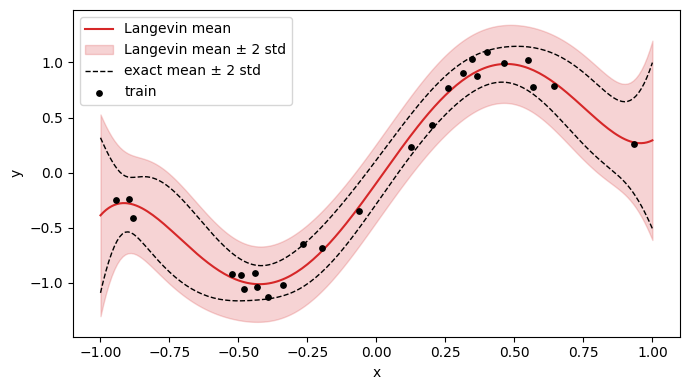

In [6]:
with torch.no_grad():
    X_test = torch.linspace(-1, 1, 201).unsqueeze(-1)
    langevin_samples = surrogate_model(X_test, particles).squeeze(-1)
    exact_samples = surrogate_model(X_test, exact_posterior.sample((2000,))).squeeze(-1)

x_plot = X_test.squeeze(-1)
_, ax = plt.subplots(figsize=(7, 4))
mean, std = langevin_samples.mean(0), langevin_samples.std(0)
ax.plot(x_plot, mean, color="tab:red", label="Langevin mean")
ax.fill_between(x_plot, mean - 2 * std, mean + 2 * std, color="tab:red", alpha=0.2, label="Langevin mean ± 2 std")
mean, std = exact_samples.mean(0), exact_samples.std(0)
ax.plot(x_plot, mean - 2 * std, color="black", ls="--", lw=1, label="exact mean ± 2 std")
ax.plot(x_plot, mean + 2 * std, color="black", ls="--", lw=1)
ax.scatter(X.squeeze(-1), Y.squeeze(-1), color="black", s=15, label="train", zorder=3)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.tight_layout()

## Particle trajectories

Each panel shows 128 particle trajectories for one coefficient, plotted against the pseudo-time $t = k h$. The particles start from $\mathcal{N}(0, \sigma_0^2)$ and are transported by the learned drift toward the posterior. The black line and gray band mark the exact posterior mean $\pm 2$ standard deviations.

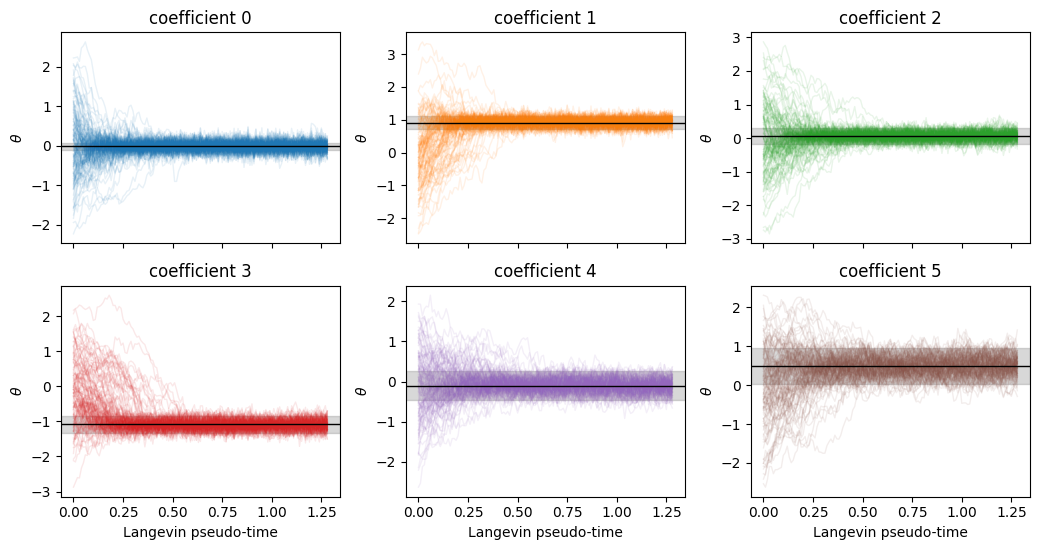

In [7]:
pseudo_time = torch.arange(trajectory.shape[0]) * group.step_size
num_shown = 128

ncols = 3
nrows = (num_params + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.8 * nrows), sharex=True)
axes = axes.flatten()

for j in range(num_params):
    ax = axes[j]
    ax.plot(pseudo_time, trajectory[:, :num_shown, j], color=f"C{j}", alpha=0.1, linewidth=1.0)
    ax.axhline(post_mean[j], color="black", lw=1)
    ax.axhspan(post_mean[j] - 2 * post_std[j], post_mean[j] + 2 * post_std[j], color="gray", alpha=0.3)
    ax.set_title(f"coefficient {j}")
    ax.set_ylabel(r"$\theta$")
for ax in axes[num_params:]:
    ax.axis("off")
for ax in axes[nrows * ncols - ncols :]:
    ax.set_xlabel("Langevin pseudo-time")

plt.tight_layout()

## Particle distributions at the start and end of the chain

Histograms of all 2000 particles at $t = 0$ and $t = T$, with the exact marginal posterior density overlaid.

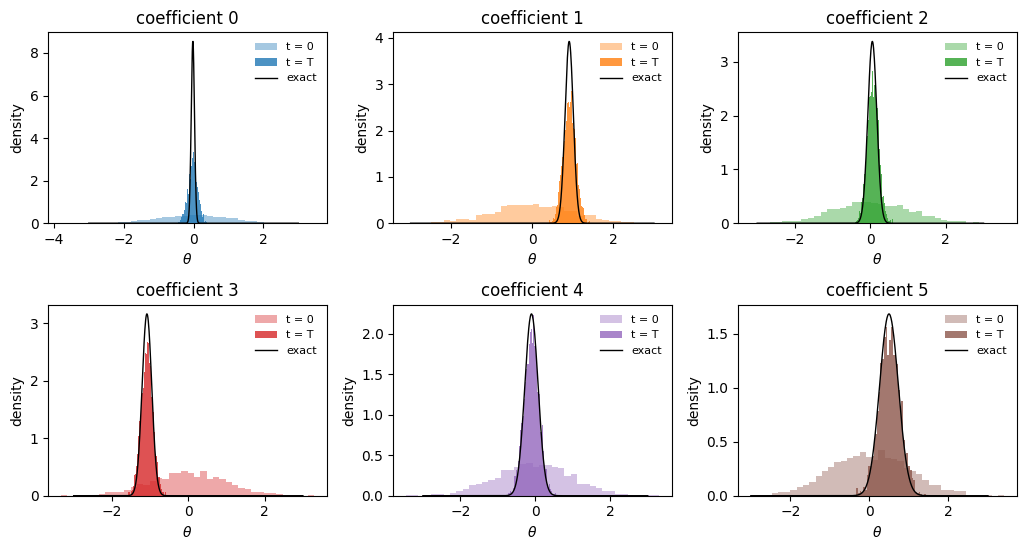

In [8]:
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.8 * nrows))
axes = axes.flatten()

for j in range(num_params):
    ax = axes[j]
    ax.hist(trajectory[0, :, j], bins=40, density=True, alpha=0.4, color=f"C{j}", label="t = 0")
    ax.hist(trajectory[-1, :, j], bins=40, density=True, alpha=0.8, color=f"C{j}", label="t = T")
    lo, hi = post_mean[j] - 5 * post_std[j], post_mean[j] + 5 * post_std[j]
    grid = torch.linspace(min(lo.item(), -3.0), max(hi.item(), 3.0), 600)
    density = torch.distributions.Normal(post_mean[j], post_std[j]).log_prob(grid).exp()
    ax.plot(grid, density, color="black", lw=1, label="exact")
    ax.set_title(f"coefficient {j}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("density")
    ax.legend(frameon=False, loc="upper right", fontsize=8)
for ax in axes[num_params:]:
    ax.axis("off")

plt.tight_layout()

## Energy and score along the chain

Distributions of the learned energy $E_\phi$ and of the drift norm $\|\nabla_\theta E_\phi\|$ at $t = 0$ and $t = T$. Since $E_\phi$ acts as a log-density, the particles move toward higher energy, and the drift shrinks once they reach the high-density region.

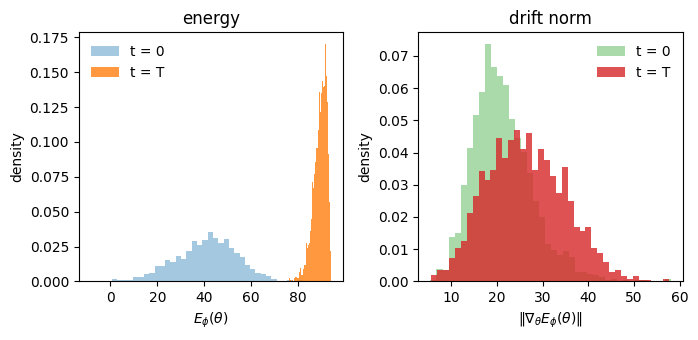

In [9]:
theta0, thetaT = trajectory[0], trajectory[-1]
with torch.no_grad():
    energy0, energyT = group._energy(theta0), group._energy(thetaT)
score0 = group._score(theta0).detach().norm(dim=1)
scoreT = group._score(thetaT).detach().norm(dim=1)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].hist(energy0, bins=40, density=True, alpha=0.4, color="C0", label="t = 0")
axes[0].hist(energyT, bins=40, density=True, alpha=0.8, color="C1", label="t = T")
axes[0].set_title("energy")
axes[0].set_xlabel(r"$E_\phi(\theta)$")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False)

axes[1].hist(score0, bins=40, density=True, alpha=0.4, color="C2", label="t = 0")
axes[1].hist(scoreT, bins=40, density=True, alpha=0.8, color="C3", label="t = T")
axes[1].set_title("drift norm")
axes[1].set_xlabel(r"$\|\nabla_\theta E_\phi(\theta)\|$")
axes[1].set_ylabel("density")
axes[1].legend(frameon=False)

plt.tight_layout()